# Question
"A midfielder has a 65% chance of making a successful pass. If he attempts 10 passes to his striker during a match, what are the chances that exactly 7 of those passes successfully reach the striker?"

# My Study 
1. For my random variable ,X, I will observe how many passes out of 10 attempts from the midfielder successfully reach the striker without being intercepted. The midfielder has a baseline 65% chance of making a successful pass on any given attempt. While this 65% probability stays constant for each individual pass, the overall likelihood of completing a cumulative total of passes changes as the number of attempts increases. 

2. On his first attempt, he has a 65% chance of making a good pass that reaches his striker. However, as he attempts more passes, stringing together a continuous streak of successful passes becomes significantly harder. While any single pass retains that same 65% chance, compounding multiple successes causes the probability of completing a long streak—such as making all 10 passes—to drop drastically.

In [2]:
import pandas as pd
from scipy.stats import binom

# Parameters: 10 passes, 65% success rate
n, p = 10, 0.65

# Create probability table for 0 to 10 successful passes
df = pd.DataFrame({
    'Passes (k)': range(n + 1),
    'Probability': binom.pmf(range(n + 1), n, p)
})
df['Percentage (%)'] = (df['Probability'] * 100).round(2)

# Display results
print(df.to_string(index=False))
print(f"\nProbability of exactly 7 passes: {df.loc[7, 'Percentage (%)']}%")

 Passes (k)  Probability  Percentage (%)
          0     0.000028            0.00
          1     0.000512            0.05
          2     0.004281            0.43
          3     0.021203            2.12
          4     0.068910            6.89
          5     0.153570           15.36
          6     0.237668           23.77
          7     0.252220           25.22
          8     0.175653           17.57
          9     0.072492            7.25
         10     0.013463            1.35

Probability of exactly 7 passes: 25.22%


# Analysis of the code
This code analyzes what are the chances of our midfielder making a perfect pass out of 10 attempts? for example, the chances of this midfielder making 1/10 successful passes is .05%, because he is such a good passer, the chances of him only  making 1 and failing at the rest 9 is almost impossible as it sits below 1%. and it goes on and on. as we reach the point where the chances of him making 7 passes out of 10 is the highest, which is 25.22%. 

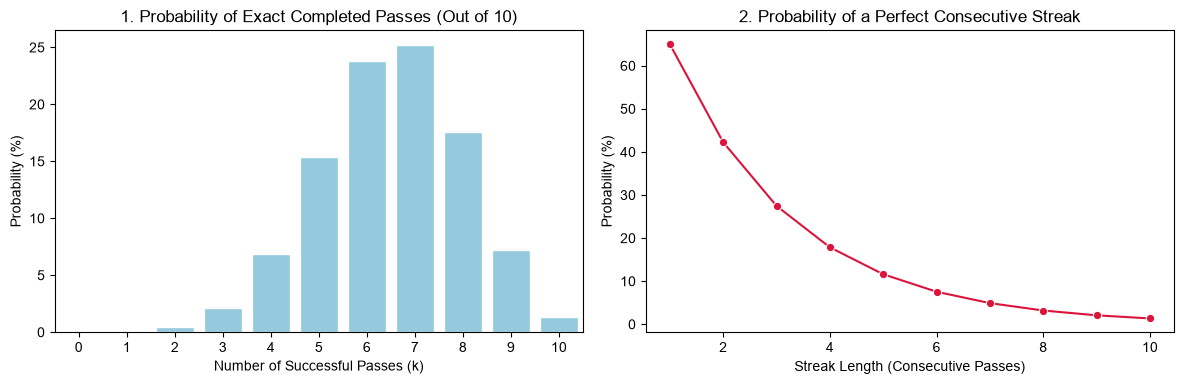

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from scipy.stats import binom

# Data
n, p = 10, 0.65
k = list(range(n + 1))
pmf = binom.pmf(k, n, p)
streak = [p**i for i in range(1, n + 1)]

# Setup plots side-by-side
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.set_theme(style="whitegrid")

# Plot 1: Binomial Distribution (Exact k passes)
sns.barplot(x=k, y=[p * 100 for p in pmf], ax=axes[0], color='skyblue')
axes[0].set_title("1. Probability of Exact Completed Passes (Out of 10)")
axes[0].set_xlabel("Number of Successful Passes (k)")
axes[0].set_ylabel("Probability (%)")

# Plot 2: Perfect Streak Probability (1 to 10 consecutive passes)
sns.lineplot(x=list(range(1, n + 1)), y=[s * 100 for s in streak], ax=axes[1], marker='o', color='crimson')
axes[1].set_title("2. Probability of a Perfect Consecutive Streak")
axes[1].set_xlabel("Streak Length (Consecutive Passes)")
axes[1].set_ylabel("Probability (%)")

plt.tight_layout()
plt.show()

In [4]:
from scipy.stats import binom

n, p = 10, 0.65

# Binomial Mean (μ = n * p) and Standard Deviation (σ = √(n * p * (1-p)))
mean = binom.mean(n, p)
std = binom.std(n, p)

print(f"Mean (Expected Passes): {mean}")
print(f"Standard Deviation: {std:.2f}")

Mean (Expected Passes): 6.5
Standard Deviation: 1.51


# Interperation of the Mean and standard deviation
Mean; The average number of succesful passes this player has is about 6 passes( or 7, as its 6.5), so out of 10 shots, he has a good chance of making a 6 or 7 succesful passes. 
Standard Deviation; 1.51 is the number that varies from the mean, so its either higher or lower by this number( in this case, 1.51 is the higher number), meaning this is an above average player. 

In [1]:
import numpy as np
from scipy.stats import binom

n, p, trials = 10, 0.65, 100_000

# 1. Theoretical Probabilities (Exact Math)
theo_7 = binom.pmf(7, n, p)

# 2. Empirical Probabilities (Simulating 100,000 sets of 10 passes)
simulations = np.random.binomial(n, p, size=trials)
emp_7 = np.mean(simulations == 7)

print(f"Theoretical P(X=7): {theo_7 * 100:.2f}%")
print(f"Empirical P(X=7):   {emp_7 * 100:.2f}%")

Theoretical P(X=7): 25.22%
Empirical P(X=7):   25.33%


# Interpretation of the Theoritical and empirical probabilities;
Interpretation of the theoritical;
with 25.22% chance, there is a 25.25% chance that he makes exactly 7 out of his 10 passes that were succesful. 
Interpretation of teh empirical;
with 25.33% chance, with more and more gamess, the chances of him making exactly 7 out of 10 passes is very high( as the theoritical and empirical percetnages are very close to each other, one being 25.22% while the other is 25.33%), meaning with more and more games, he is most likely to make 7 out of 10 passes, rather than fewer games, which could alter these data. 